In [24]:
import pandas as pandamanicobar
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,MinMaxScaler



In [63]:
df = pandamanicobar.read_csv('./diabetes.csv')

# df["Outcome"] = df["Outcome"].map({
#     1: "Diabetic",
#     0: "Non-Diabetic"
# })
print(df.head())
print(df.columns)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    object 
dtypes: float64(2), int64(6), object(1)
memory usage: 54.1+ KB


In [ ]:
print(df.isnull().sum())

# features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
#        'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
# for feat in features:
#     print(df[feat].isnull().sum())



Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [43]:
df.describe()
   

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000


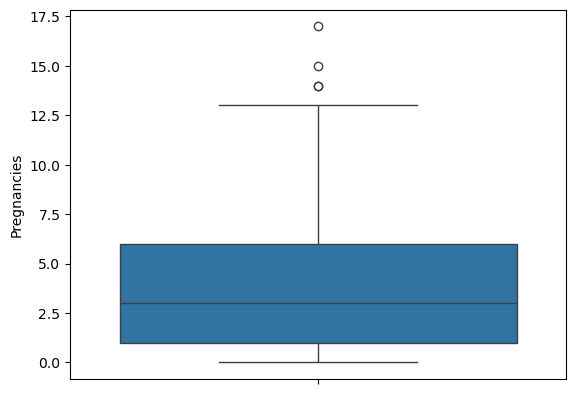

In [ ]:

sns.boxplot(y='Pregnancies',data=df)
plt.show()

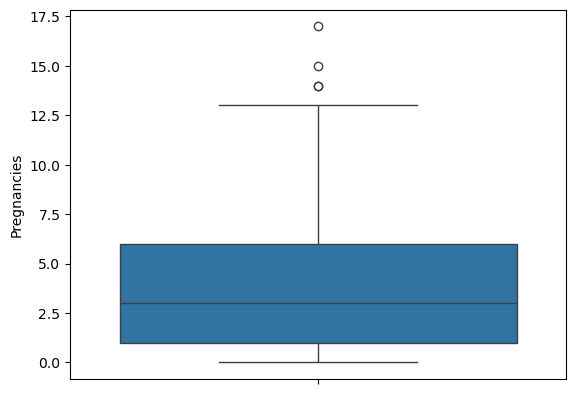

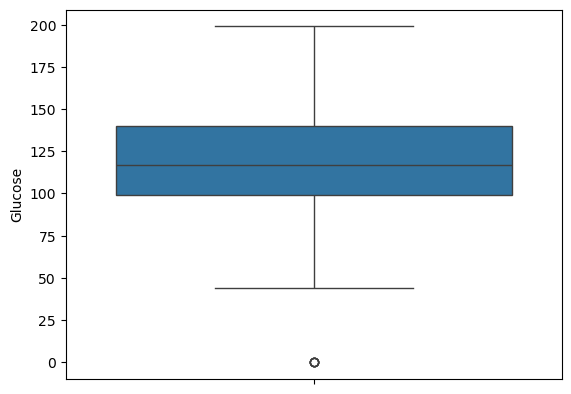

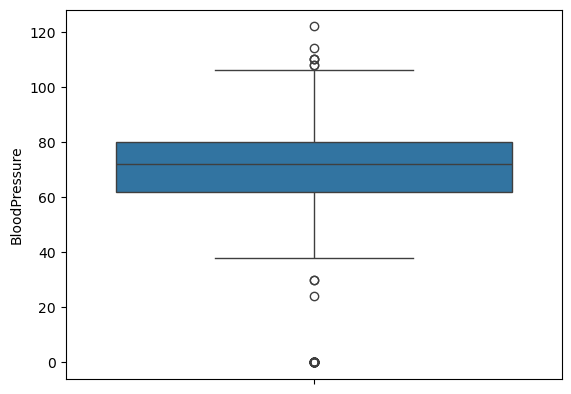

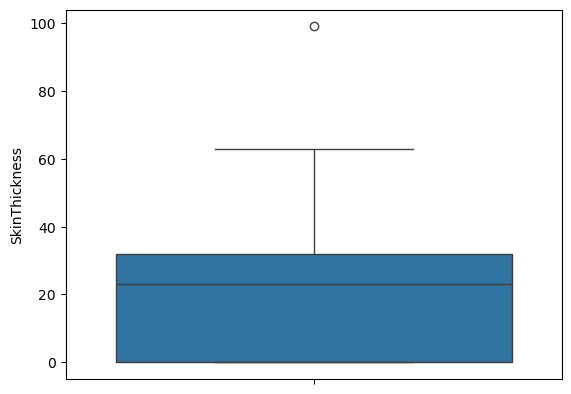

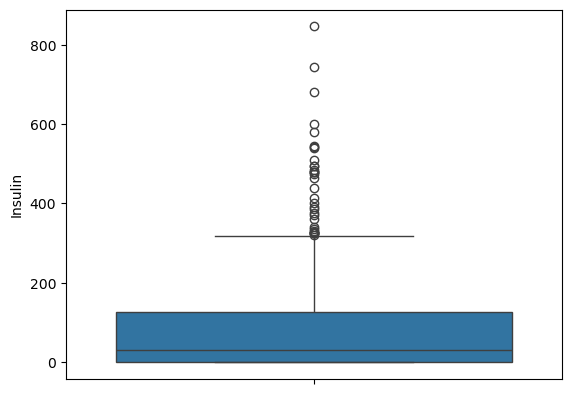

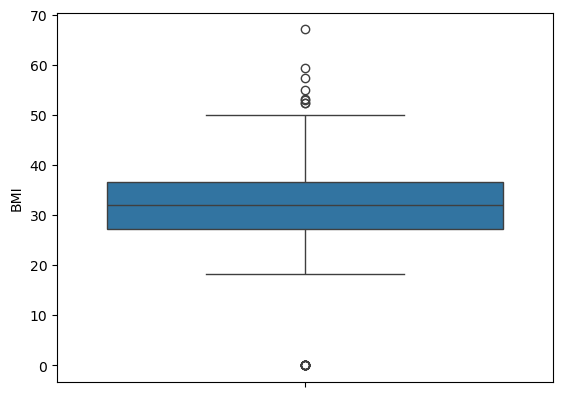

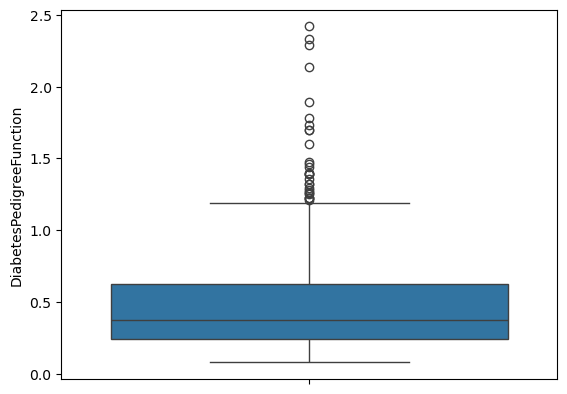

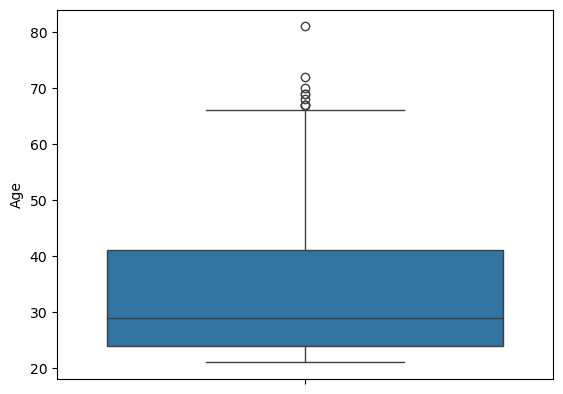

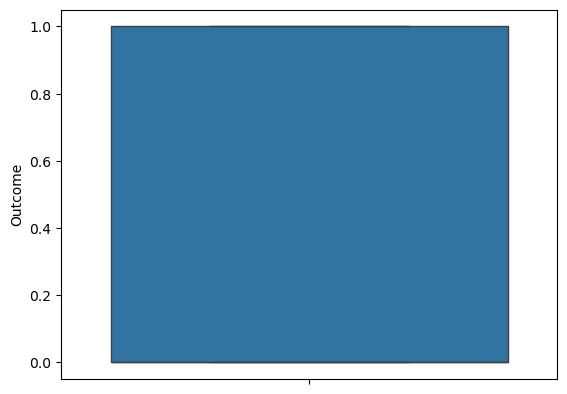

In [65]:
features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
for feat in features:
    sns.boxplot(y=feat,data=df)
    plt.show()

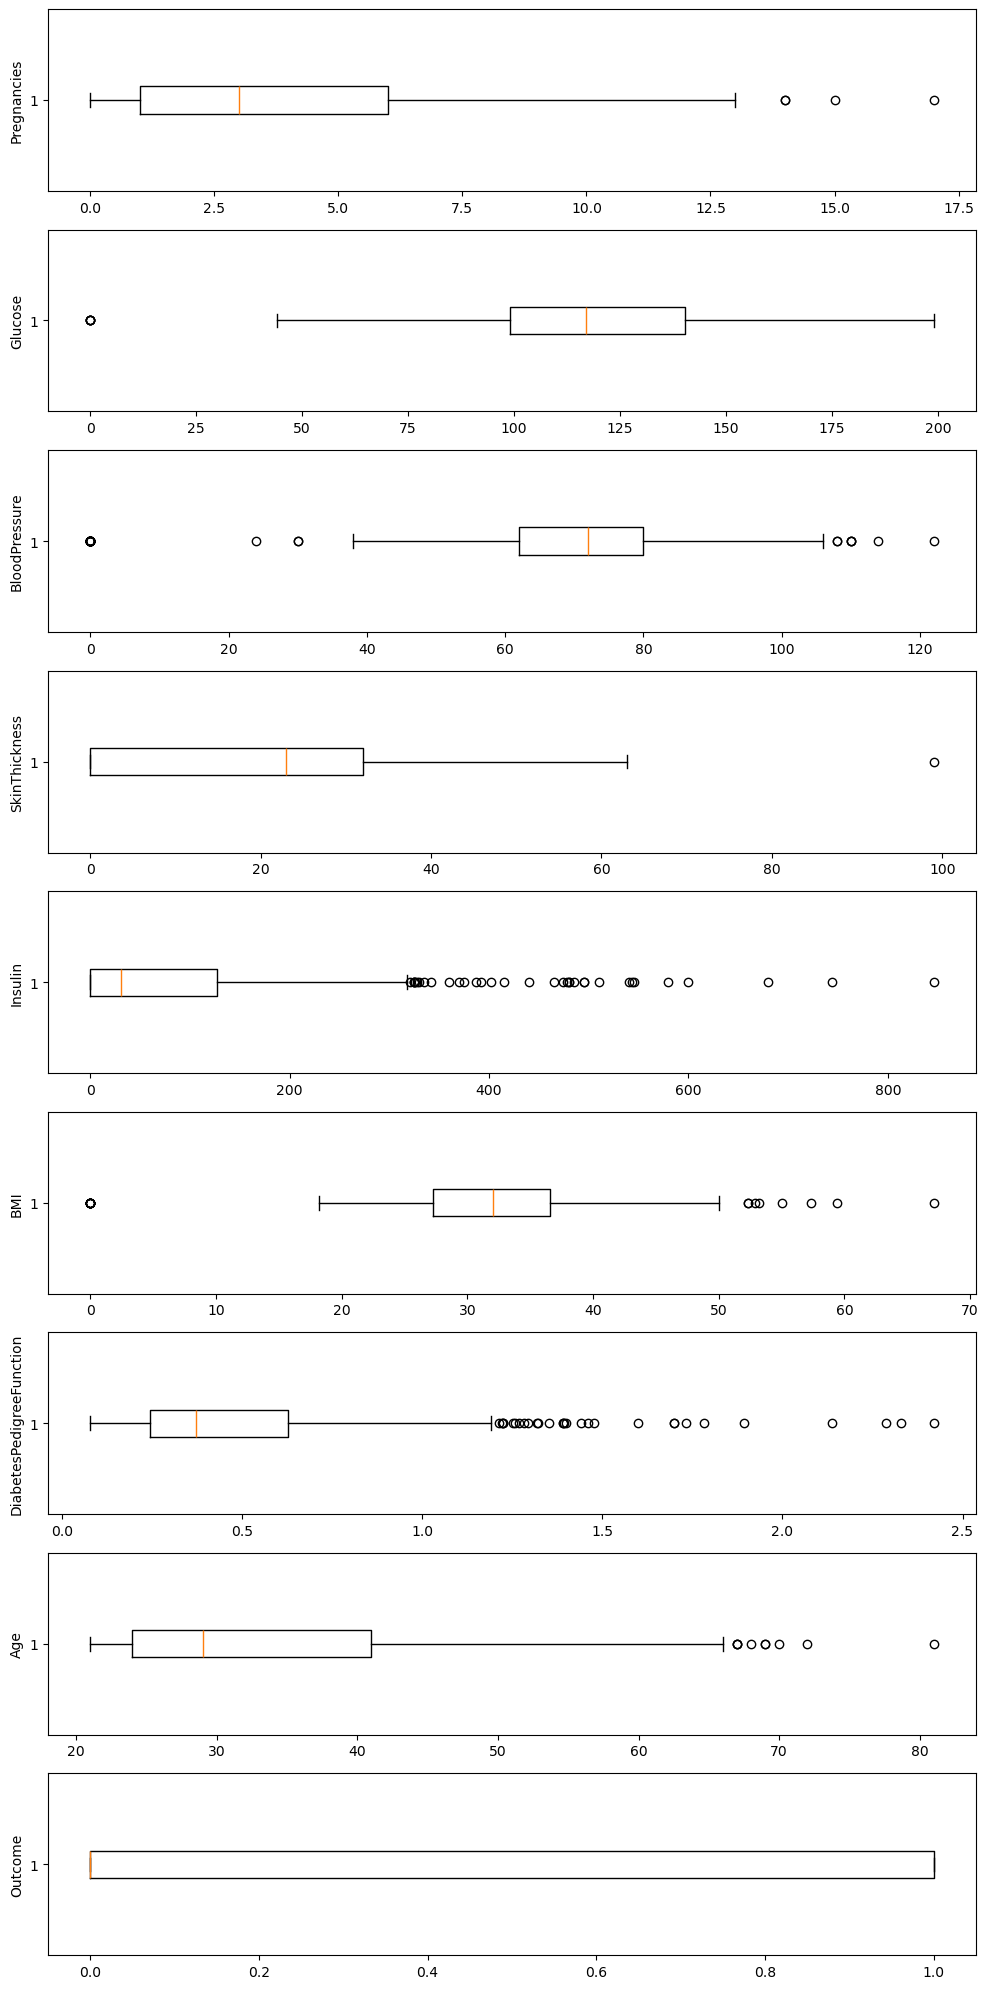

In [66]:
fig,guu = plt.subplots(len(df.columns),1,figsize=(10,20))
for i,col in enumerate(df.columns):
    guu[i].boxplot(df[col],vert=False)
    guu[i].set_ylabel(col)
plt.tight_layout()
plt.show()

In [69]:
# removing outliers using IQR method(Inter Quartile Range)

a = []
for i in range(0,101):
    a.append(i)
p=np.percentile(a,[25,75])
print(p)

[25. 75.]


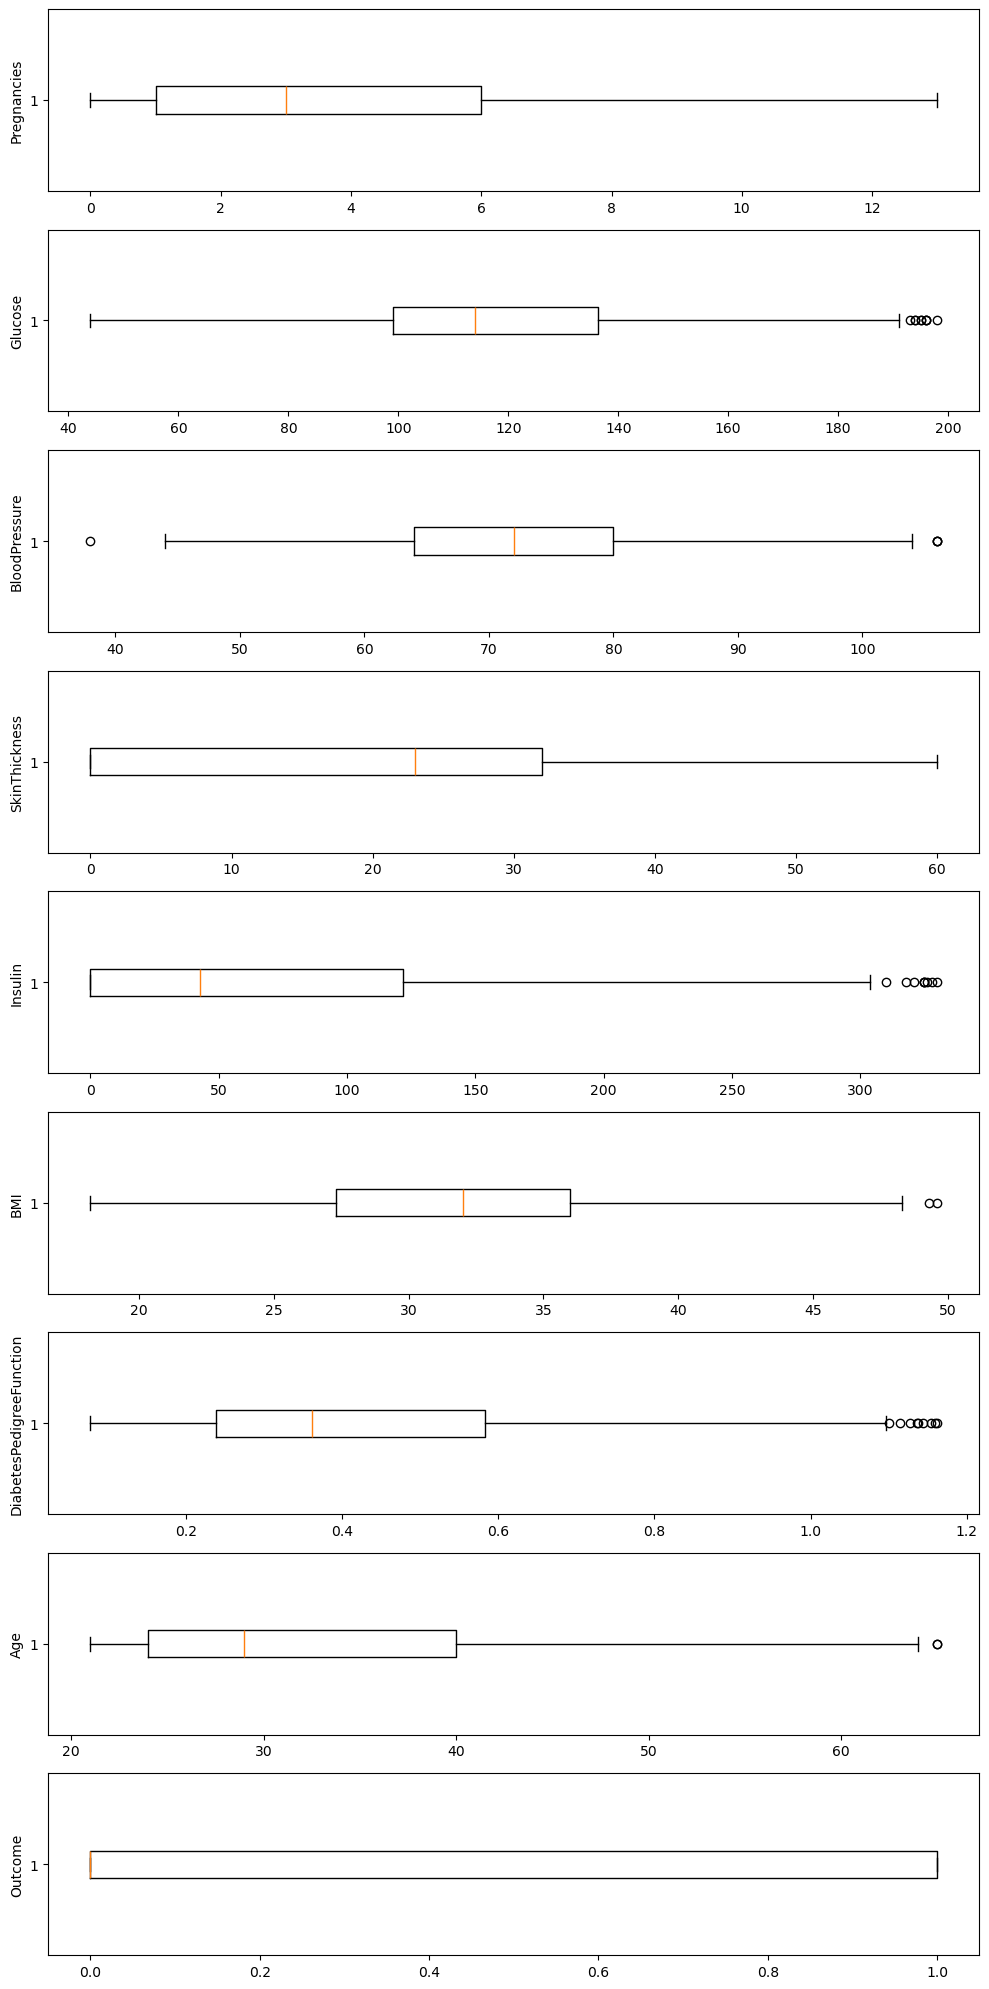

In [89]:
# IQR = q3-q1

clean_df = df

for feat in features:
    q1,q3 = np.percentile(clean_df[feat],[25,75])
    iqr = q3-q1

    lb = q1-(1.5*iqr)
    ub = q3+(1.5*iqr)
    clean_df = clean_df[(clean_df[feat]>=lb) & (clean_df[feat] <=ub)]


fig,guu = plt.subplots(len(clean_df.columns),1,figsize=(10,20))
for i,col in enumerate(clean_df.columns):
    guu[i].boxplot(clean_df[col],vert=False)
    guu[i].set_ylabel(col)
plt.tight_layout()
plt.show()


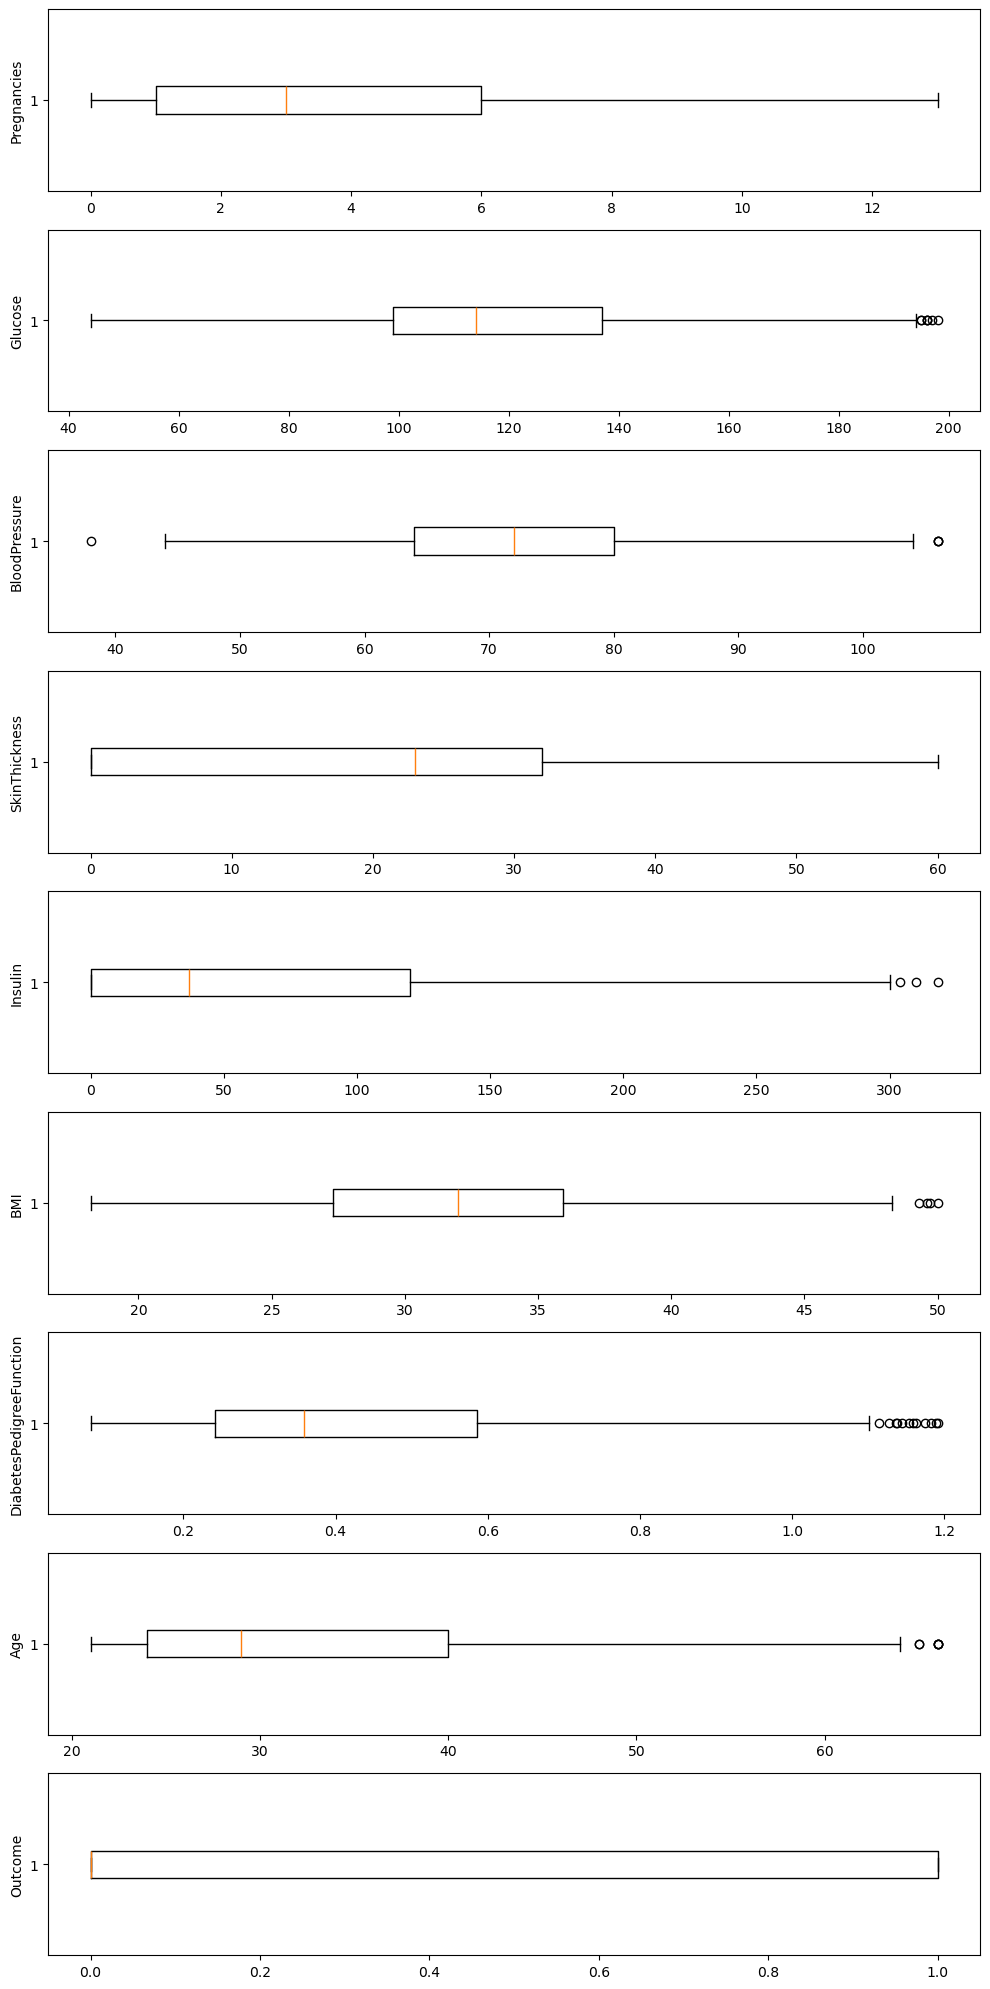

In [91]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 -Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
cleanest_df = df[((df>=lower) & (df <=upper)).all(axis=1)]

fig,guu = plt.subplots(len(cleanest_df.columns),1,figsize=(10,20))
for i,col in enumerate(cleanest_df.columns):
    guu[i].boxplot(cleanest_df[col],vert=False)
    guu[i].set_ylabel(col)
plt.tight_layout()
plt.show()



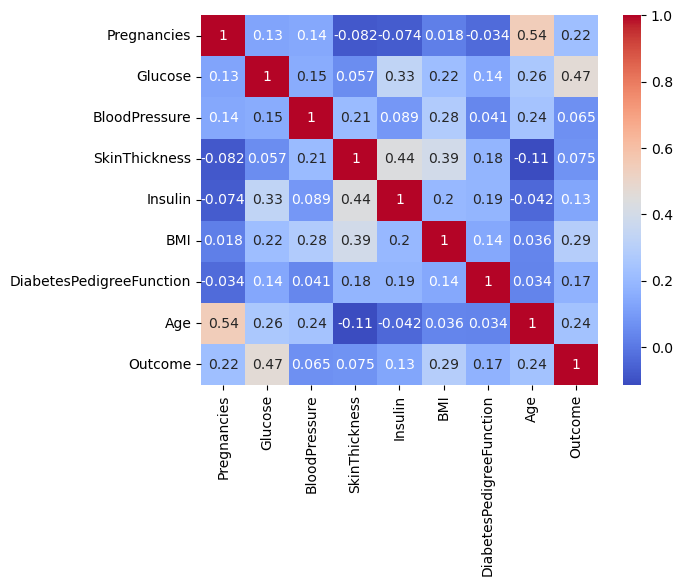

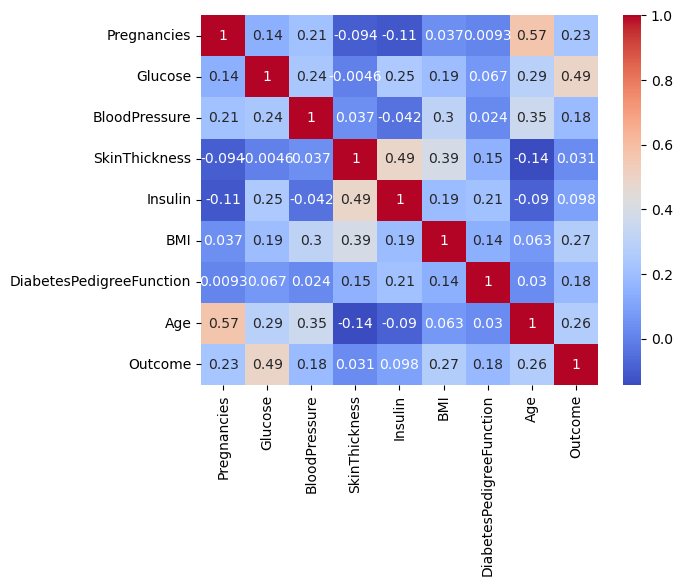

In [93]:
# Corelation Analysis

corr = df.corr()
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.show()

corr = cleanest_df.corr()
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.show()


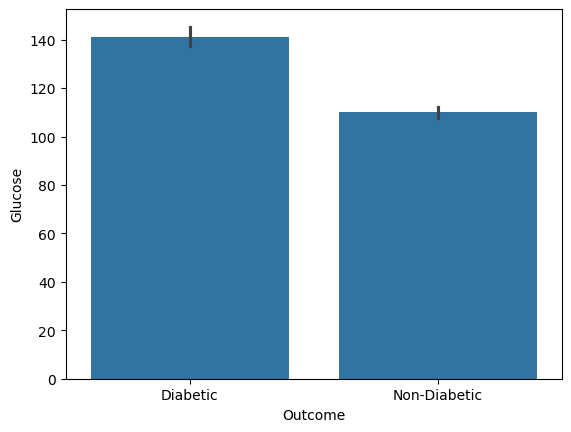

In [28]:
X=df["Outcome"]
Y=df["Glucose"]

sns.barplot(x='Outcome',y='Glucose',data=df)
plt.show()